In [ ]:
# 必要なライブラリのインストールと、torchaoのアップデート
!pip install -q -U diffusers transformers accelerate safetensors torchao

import warnings
warnings.filterwarnings("ignore")

import torch
from diffusers import StableDiffusionPipeline

# GPUが利用可能かチェックし、デバイスを選択
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("【警告】GPUが認識されていません。Google Colabのメニュー『ランタイム』->『ランタイムのタイプを変更』から『T4 GPU』を選択してください。")

# モデルIDの定義
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# VRAM・RAM効率化のため、torch_dtype=torch.float16を指定してロード (CPUの場合はfloat32で読み込む必要があります)
torch_dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch_dtype
)
pipe = pipe.to(device)

print(f"環境準備およびモデルのロードが完了しました。デバイス: {device}")

【警告】GPUが認識されていません。Google Colabのメニュー『ランタイム』->『ランタイムのタイプを変更』から『T4 GPU』を選択してください。


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

環境準備およびモデルのロードが完了しました。デバイス: cpu


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/782k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.50M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  303MB            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

--- 入力した元の日本語文章 ---
プロンプト: 美しい幻想的な湖と夕暮れの空、満開 of 桜の木、高品質、ディテール描写
ネガティブプロンプト: 低品質、ぼやけた画像、奇妙な構造、変形

--- 翻訳された英語 ---
Prompt: A beautiful, fantasy lake and evening sky full of cherry trees, high quality and detail.
Negative Prompt: Low quality, poor image, strange structure, deformation.


  0%|          | 0/10 [00:00<?, ?it/s]

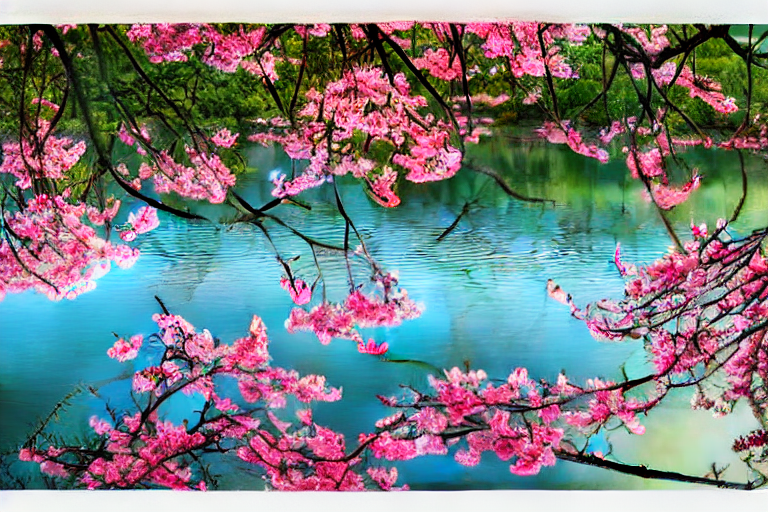

In [ ]:
# ===========================
# 2. セル2  プロンプトと画像生成
# ===========================
import torch
from transformers import MarianMTModel, MarianTokenizer

# 1. 元の日本語プロンプトとネガティブプロンプトの設定
prompt_ja = "美しい幻想的な湖と夕暮れの空、満開 of 桜の木、高品質、ディテール描写"
negative_prompt_ja = "低品質、ぼやけた画像、奇妙な構造、変形"

# 7. 日本語から英語への翻訳処理（MarianMTを直接使用）
model_name = "Helsinki-NLP/opus-mt-ja-en"
tokenizer = MarianTokenizer.from_pretrained(model_name)
translator_model = MarianMTModel.from_pretrained(model_name)

def translate(text):
    inputs = tokenizer(text, return_tensors="pt", padding=True)
    with torch.no_grad():
        translated = translator_model.generate(**inputs)
    return tokenizer.decode(translated[0], skip_special_tokens=True)

prompt_en = translate(prompt_ja)
negative_prompt_en = translate(negative_prompt_ja)

# 翻訳された英語文章を出力
print("--- 入力した元の日本語文章 ---")
print(f"プロンプト: {prompt_ja}")
print(f"ネガティブプロンプト: {negative_prompt_ja}")
print("\n--- 翻訳された英語 ---")
print(f"Prompt: {prompt_en}")
print(f"Negative Prompt: {negative_prompt_en}")

# 3. 生成画像サイズの設定
width = 768
height = 512

# 4. 画像生成パラメータを変数として設定
num_inference_steps = 10
guidance_scale = 7.5

# 5. シード値（seed）の設定
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

# 6. 画像の生成
image = pipe(
    prompt=prompt_en,
    negative_prompt=negative_prompt_en,
    width=width,
    height=height,
    num_inference_steps=num_inference_steps,
    guidance_scale=guidance_scale,
    generator=generator
).images[0]

# 生成画像の表示
display(image)